# 06. ODE-LSTM — 용담댐 시간 유입량 예측 (입력세트 A / B / C)

**모델**: ODE-LSTM (`model: odelstm`) — 순환(연속시간)
**한 줄 요약**: LSTM 은닉 상태를 상미분방정식(ODE)으로 연속시간 전개. 불규칙·다중 해상도 입력을 하나의 연속 상태로 처리.

이 노트북은 모델 비교 연구(10개 모델 × 3개 입력세트)의 **ODE-LSTM 부분**입니다. 모든 모델 노트북이 같은 구성을 가집니다.

1. 모델 설명 (논문 methodology용)
2. 자료와 실험 설정
3. 학습 (입력세트 A, B, C) 과 학습곡선
4. 학습 / 검증 / 테스트 기간 성능
5. 수문곡선 · 산점도 · 유량지속곡선
6. 홍수 첨두 재현
7. 결과 해석
8. 요약 (비교 노트북 `11_Comparison_Overall.ipynb`, `12_Comparison_Peaks.ipynb` 에서 사용하는 `results/odelstm_<set>/` 생성)

**연구 설정 요약**

| 항목 | 내용 |
|---|---|
| 대상 | 용담댐 (유역면적 930.42 km²) 시간 유입량 (m³/s) |
| 기간 | 2006-01-01 ~ 2025-12-31 (20년, 175,320 시간) |
| 학습 / 검증 / 테스트 | 2006–2017 (12년) / 2018–2021 (4년) / 2022–2025 (4년) |
| 입력세트 A | 유역평균 강수량 `rf_avg` (1변수) |
| 입력세트 B | 관측소별 강수량 `rf_<관측소>` × 7 (7변수) |
| 입력세트 C | A + B (8변수) |
| 해상도 | 시간(hourly). MTS-LSTM만 일(daily) 강우를 추가로 사용 |
| 공통 학습 설정 | Adam, lr 1e-3, batch 256, MSE, seq_length 720 h, epoch 30–50 (early stopping patience 5), seed 111 |
| 평가 epoch | 검증 loss가 최소인 epoch (early stopping은 학습을 멈출 뿐 가중치를 되돌리지 않음) |
| 데이터셋 클래스 | `hourlycsv` (`data/YDDam_paper/`) — `prepare_data.py` 로 생성 |
| 설정 파일 | `configs/<model>_<set>.yml` — `make_configs.py` 로 생성 |
| 공통 코드 | `common.py` (run 관리·평가·그림), `model_docs.py` (모델 설명) |



## 1. 모델 설명 (Methodology)

**ODE-LSTM (Lechner & Hasani, 2020; NeuralHydrology `odelstm`)**

LSTM 셀 뒤에 **ODE-RNN** 을 붙여, 두 관측 사이의 시간 간격 $\Delta t$ 동안 은닉 상태가 연속적으로 변하도록 만든 모델이다.

$$
h_{t} = \mathrm{ODESolve}\big(f_\theta,\; h_{t-1}^{\mathrm{LSTM}},\; \Delta t\big), \qquad
\frac{dh}{d\tau} = f_\theta(h, x_t)
$$

여기서 $f_\theta$는 작은 신경망이고, `ode_method: euler` 와 `ode_num_unfolds: 4` 는 각 시간 간격을 4단계의 오일러법으로 적분함을 뜻한다.
NeuralHydrology 구현은 MTS-LSTM과 같은 2해상도 입력(1D: 365일, 1h: 336시간)을 받되, 학습 중에는 오래된 구간을 **무작위 해상도(5D~1D)** 로
재집계해 모델이 다양한 $\Delta t$ 를 경험하게 한다. 마지막 24시간의 시간 단위 예측만 평가한다.

### 1.1 수문학적 관점에서의 특징

- 수문학적으로 **저류 상태의 연속시간 전개**(감수곡선 $dS/dt = -kS$ 와 유사)를 직접 학습하는 셈이어서, 관측 간격이 일정하지 않거나 해상도가
  섞인 자료에 적합하다.
- 본 자료는 시간 간격이 일정하므로 ODE의 장점이 크게 드러나지는 않지만, MTS-LSTM과 같은 입력(1년 일 강우 + 14일 시강우)을 **하나의
  연속 상태**로 처리한다는 점에서 MTS-LSTM의 대안으로 비교할 가치가 있다.
- 단, 이 모델은 **일 단위 자료를 쓰지 않는다**: 두 해상도 모두 `hourly` 파일의 시강우를 집계해 만든다(설정의 `forcings: [hourly]`).

### 1.2 본 연구에서의 설정

| 항목 | 값 | 이유 |
|---|---|---|
| `use_frequencies` | [1D, 1h] | 두 해상도(시강우를 내부에서 일 단위로 집계) |
| `seq_length` / `predict_last_n` | {1D: 365, 1h: 336} / {1D: 1, 1h: 24} | MTS-LSTM과 동일 |
| `ode_method` / `ode_num_unfolds` | euler / 4 | 오일러법 4단계 적분 |
| `ode_random_freq_lower_bound` | 5D | 학습 시 무작위 재집계의 가장 거친 해상도 |
| `regularization` | tie_frequencies | 해상도 간 일관성 |

### 참고문헌

- Lechner, M., & Hasani, R. (2020). Learning long-term dependencies in irregularly-sampled time series. *arXiv:2006.04418*.
- Gauch, M. et al. (2021). (ODE-LSTM과 MTS-LSTM의 수문 비교) *HESS*, 25, 2045–2062.


## 2. 자료와 실험 설정

`common.py` 가 run 디렉터리 탐색, 평가, 그림을 모두 담당하므로 노트북 코드는 짧습니다. 아래 셀은 공통 설정을 불러오고 그림 스타일(큰 글꼴,
300 dpi 저장)을 지정합니다.

In [1]:
%matplotlib inline
import sys, warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))
import common
from common import SETS, MODEL_NAME, MODEL_COLOR, SET_COLOR, SET_STYLE, PERIODS, PERIOD_LABEL
from model_docs import MODEL_DOCS, MODEL_FAMILY

warnings.filterwarnings("ignore", category=FutureWarning)
common.set_plot_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

MODEL = "odelstm"
NAME = MODEL_NAME[MODEL]
print(NAME, "->", common.MODEL_SPECS[MODEL]["nh_model"])

ODE-LSTM -> odelstm


### 2.1 자료 개요

연도별 유역평균 강수량과 유입량(평균·최대)입니다. 음영은 학습(회색) / 검증(주황) / 테스트(녹색) 기간입니다.
테스트 기간(2022–2025)에는 2023년과 2024년의 큰 홍수가 포함되어 있고, 학습 기간에는 2020년(최대 4,395 m³/s)이 **포함되지 않는다**는 점에 유의합니다
(2020년은 검증 기간). 즉 모델은 학습에서 본 적 없는 크기의 홍수를 검증·테스트에서 재현해야 하며, 이것이 모델 간 외삽 능력 차이를 드러냅니다.

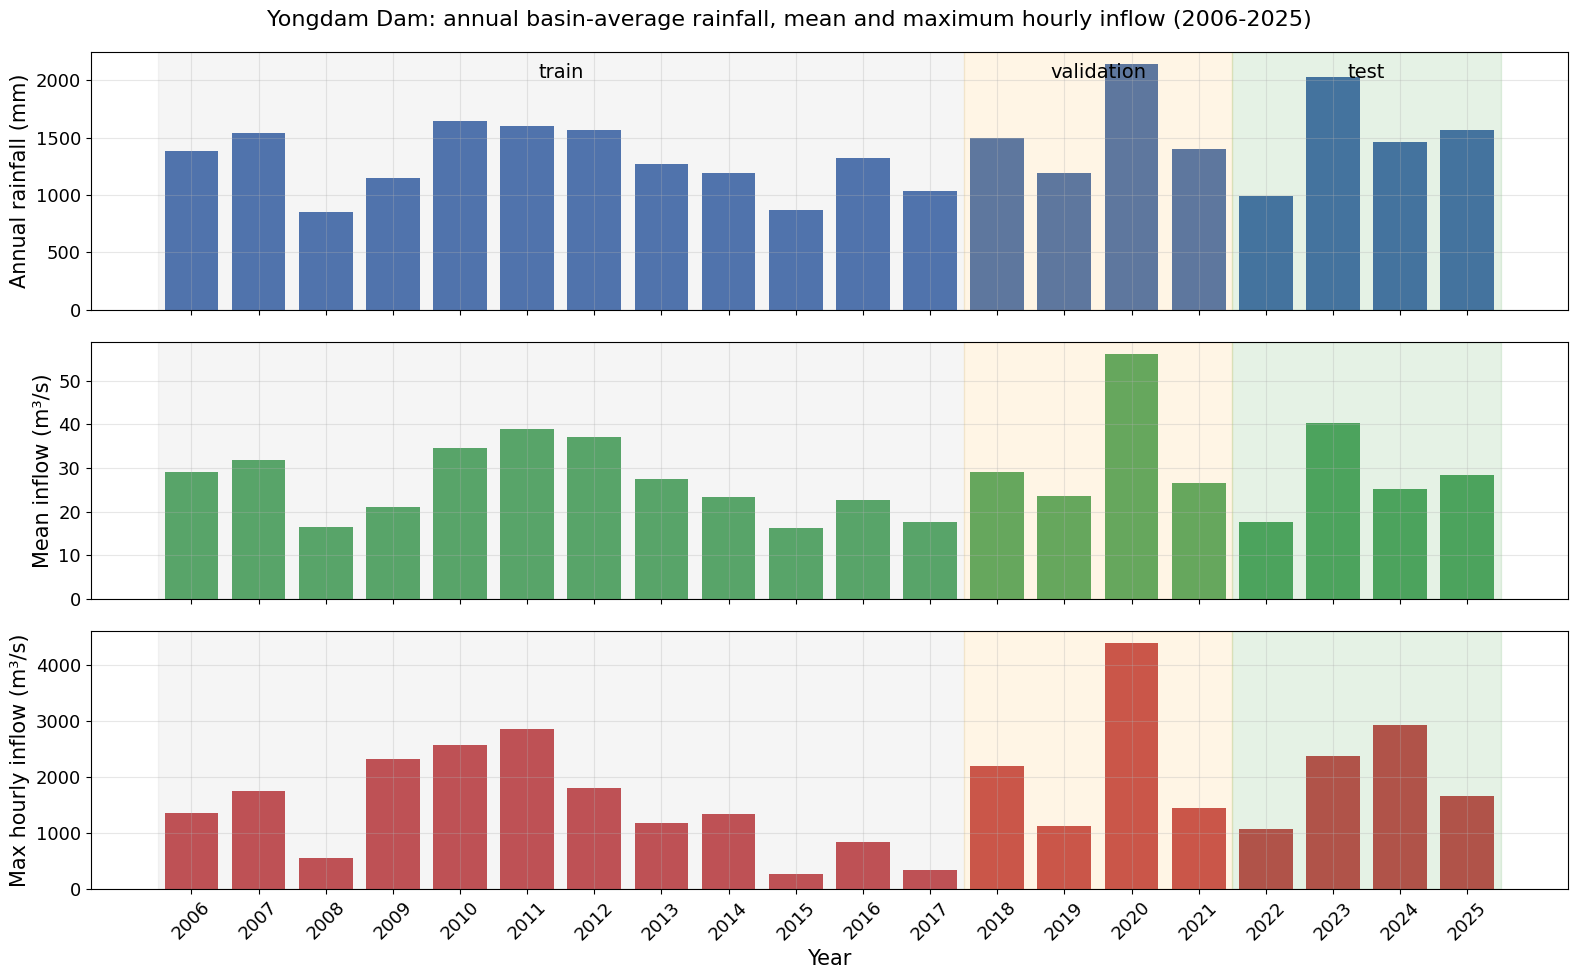

In [2]:
rain = common.load_rainfall(["rf_avg"])["rf_avg"]
inflow = common.load_observed_inflow()
annual = pd.DataFrame({"rain_mm": rain.resample("YE").sum(), "inflow_mean": inflow.resample("YE").mean(),
                       "inflow_max": inflow.resample("YE").max()})
annual.index = annual.index.year
annual = annual.loc[2006:2025]

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
axes[0].bar(annual.index, annual["rain_mm"], color="#4c72b0")
axes[0].set_ylabel("Annual rainfall (mm)")
axes[1].bar(annual.index, annual["inflow_mean"], color="#55a868")
axes[1].set_ylabel("Mean inflow (m³/s)")
axes[2].bar(annual.index, annual["inflow_max"], color="#c44e52")
axes[2].set_ylabel("Max hourly inflow (m³/s)")
for ax in axes:
    ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
    ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
    ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
axes[0].text(2011.5, axes[0].get_ylim()[1] * 0.9, "train", ha="center", fontsize=14)
axes[0].text(2019.5, axes[0].get_ylim()[1] * 0.9, "validation", ha="center", fontsize=14)
axes[0].text(2023.5, axes[0].get_ylim()[1] * 0.9, "test", ha="center", fontsize=14)
axes[2].set_xlabel("Year")
axes[2].set_xticks(annual.index)
axes[2].tick_params(axis="x", rotation=45)
fig.suptitle("Yongdam Dam: annual basin-average rainfall, mean and maximum hourly inflow (2006-2025)", fontsize=16)
fig.tight_layout()
plt.show()


### 2.2 입력세트별 설정 파일

세 입력세트의 설정은 `dynamic_inputs` (와 모델에 따라 그에 연동된 몇 개 키)만 다릅니다. 아래 표는 공통 설정과 다른 항목만 보여 줍니다.
전체 파일은 `configs/odelstm_<set>.yml` 입니다.

In [3]:
rows = {}
for s in SETS:
    rows[f"Set {s}"] = {k: str(v) for k, v in common.model_specific_config(MODEL, s).items()}
cfg_table = pd.DataFrame(rows).fillna("")
display(cfg_table)
print(Path(common.config_path(MODEL, "A")).read_text())

,Set A,Set B,Set C
experiment_name,odelstm_A,odelstm_B,odelstm_C
seq_length,"{'1D': 365, '1h': 336}","{'1D': 365, '1h': 336}","{'1D': 365, '1h': 336}"
predict_last_n,"{'1D': 1, '1h': 24}","{'1D': 1, '1h': 24}","{'1D': 1, '1h': 24}"
model,odelstm,odelstm,odelstm
hidden_size,64,64,64
initial_forget_bias,3,3,3
output_dropout,0.4,0.4,0.4
use_frequencies,"['1D', '1h']","['1D', '1h']","['1D', '1h']"
ode_method,euler,euler,euler
ode_num_unfolds,4,4,4


experiment_name: odelstm_A
run_dir: null
train_basin_file: YDDam_basin.txt
validation_basin_file: YDDam_basin.txt
test_basin_file: YDDam_basin.txt
train_start_date: 01/01/2006
train_end_date: 31/12/2017
validation_start_date: 01/01/2018
validation_end_date: 31/12/2021
test_start_date: 01/01/2022
test_end_date: 31/12/2025
seed: 111
device: cuda:0
validate_every: 1
validate_n_random_basins: 1
metrics:
- NSE
- KGE
head: regression
output_activation: linear
optimizer: Adam
loss: MSE
learning_rate:
  0: 0.001
batch_size: 256
epochs: 50
clip_gradient_norm: 1
early_stopping: true
patience_early_stopping: 5
minimum_epochs_before_early_stopping: 30
patience_dynamic_learning_rate: 3
factor_dynamic_learning_rate: 0.5
seq_length:
  1D: 365
  1h: 336
predict_last_n:
  1D: 1
  1h: 24
num_workers: 4
log_interval: 100
log_tensorboard: false
log_n_figures: 0
save_weights_every: 1
save_validation_results: false
dataset: hourlycsv
data_dir: ../../data/YDDam_paper
forcings:
- hourly
target_variables:
- in

## 3. 학습

`common.train()` 은 완료된 run (`runs/odelstm_<set>_<날짜>_<시각>/`) 이 있으면 학습을 건너뛰고, 없으면 `nh-run train` 을 서브프로세스로
실행합니다 (`train_all.py` 로 미리 학습해 두어도 같은 run 을 사용합니다). 이어서 `common.evaluate_run()` 이

1. `output.log` 에서 epoch별 학습/검증 loss 와 검증 NSE/KGE 를 읽고,
2. 검증 loss 최소 epoch 을 골라 학습·검증·테스트 기간을 평가(`nh-run evaluate`)하고,
3. 시간 단위 예측을 m³/s 로 통일해 지표를 계산한 뒤 `results/odelstm_<set>/` 에 저장합니다.

In [4]:
summaries, histories, preds = {}, {}, {}
for s in SETS:
    run_dir = common.train(MODEL, s, in_process=False)
    summaries[s] = common.evaluate_run(MODEL, s, run_dir)
    histories[s] = common.load_saved_history(MODEL, s)
    preds[s] = common.load_saved_predictions(MODEL, s)
    print(f"Set {s}: run={summaries[s]['run_dir']}  epochs={summaries[s]['epochs_trained']}  best={summaries[s]['best_epoch']}  "
          f"params={summaries[s]['n_parameters']:,}  {summaries[s]['epoch_time_mean_s']:.0f} s/epoch")

[odelstm_A] completed run found, skipping training: odelstm_A_2010_234729
Set A: run=odelstm_A_2010_234729  epochs=50  best=49  params=25,537  26 s/epoch
[odelstm_B] completed run found, skipping training: odelstm_B_2110_001249
Set B: run=odelstm_B_2110_001249  epochs=50  best=49  params=27,073  27 s/epoch
[odelstm_C] completed run found, skipping training: odelstm_C_2110_003916


Set C: run=odelstm_C_2110_003916  epochs=45  best=40  params=27,329  32 s/epoch


### 3.1 학습곡선

왼쪽: 학습 loss(표준화된 MSE), 가운데: 검증 loss, 오른쪽: 검증 기간(2018–2021) NSE. 점선은 검증 loss 최소 epoch(평가에 쓴 체크포인트)입니다.
early stopping 은 30 epoch 이후 검증 loss 가 5 epoch 연속 개선되지 않으면 학습을 멈춥니다.

- 학습 loss 가 계속 내려가는데 검증 loss 가 올라가면 **과적합**, 둘 다 높은 채 머물면 **표현력 부족 또는 학습률 문제**입니다.
- 검증 NSE 가 들쭉날쭉하면 2020년 대홍수(검증 기간) 재현이 epoch 마다 흔들린다는 뜻입니다.

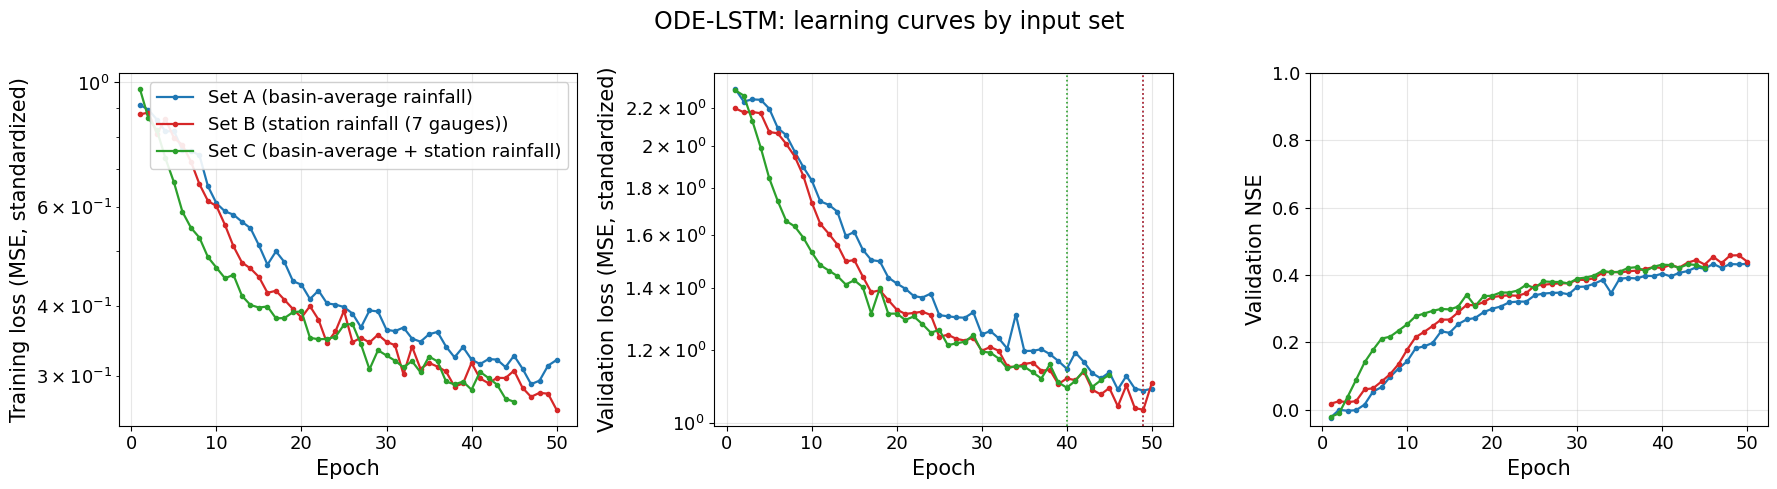

In [5]:
fig = common.plot_learning_curves(histories, title=f"{NAME}: learning curves by input set",
                                  labels={s: f"Set {s} ({common.INPUT_SET_NAMES[s]})" for s in SETS},
                                  colors=SET_COLOR, styles={s: "-" for s in SETS},
                                  best_epochs={s: summaries[s]["best_epoch"] for s in SETS})
common.save_fig(fig, f"{MODEL}_learning_curves")
plt.show()

## 4. 학습 / 검증 / 테스트 기간 성능

모든 지표는 **시간 단위, m³/s** 로 계산합니다 (MC-LSTM 의 mm/h 예측도 변환). 지표의 의미:

| 지표 | 의미 | 이상값 |
|---|---|---|
| NSE | 관측 평균 대비 설명력. 제곱오차 기반이라 **홍수(고유량)** 에 민감 | 1 |
| KGE | 상관(r)·변동성비(α)·편향비(β)를 함께 보는 지표 | 1 |
| RMSE / MAE | 오차의 크기 (m³/s) | 0 |
| PBIAS | 총량 편향(%) (+ 과대, − 과소) | 0 |
| Alpha-NSE / Beta-NSE | 표준편차 비 / 평균 편향(관측 표준편차로 정규화) | 1 / 0 |
| FHV / FMS / FLV | 유량지속곡선의 고유량(상위 2%) / 중간 구간 기울기 / 저유량(하위 30%) 편향(%) | 0 |
| Peak-Timing | 관측 첨두(자동 탐지)의 시각 오차 평균(h) | 0 |
| Peak-MAPE | 자동 탐지된 모든 첨두의 평균 절대 백분율 오차(%) | 0 |
| Missed-Peaks | 자동 탐지 첨두 중 예측이 놓친 비율 | 0 |

(첨두 자동 탐지는 라이브러리 기본 규칙으로 작은 첨두까지 포함하므로 값이 큽니다. 큰 홍수사건에 대한 분석은 6절과 `" + NB_PEAKS + "` 참고.)

In [6]:
rows = []
for s in SETS:
    for p in PERIODS:
        rows.append({"set": s, "period": p, **summaries[s]["metrics"][p]})
metrics_long = pd.DataFrame(rows).set_index(["set", "period"])[common.MAIN_METRICS]
display(metrics_long.round(3))
metrics_long.to_csv(common.RESULTS_DIR / f"{MODEL}_metrics_by_period.csv")

NSE    KGE    RMSE     MAE   PBIAS  Pearson-r  Alpha-NSE  Beta-NSE     FHV     FMS      FLV  Peak-Timing  Peak-MAPE  Missed-Peaks
set period                                                                                                                                         
A   train       0.548  0.523  47.529  15.151  -3.705      0.760      0.590    -0.014 -29.676  46.651   94.392        6.314     64.819         0.718
    validation  0.438  0.353  87.771  18.843 -14.838      0.722      0.435    -0.043 -46.890  67.511   98.001        5.341     65.266         0.728
    test        0.555  0.505  57.794  16.232   4.846      0.775      0.561     0.016 -37.341  -0.844   94.755        4.635     53.448         0.730
B   train       0.584  0.532  45.747  14.393 -11.584      0.789      0.598    -0.043 -28.648  34.191 -126.390        6.111     66.954         0.710
    validation  0.450  0.365  86.829  19.013 -20.249      0.718      0.468    -0.059 -42.352  57.736   73.774        4.951     67.326         0.753
    test        0.580  0.532  56.151  15.071  -1.360      0.789      0.582    -0.004 -33.237  -8.676   94.167        4.442     51.936         0.740
C   train       0.558  0.522  47.151  13.973  -5.407      0.770      0.585    -0.020 -28.521   7.052   95.117        6.304     67.114         0.693
    validation  0.432  0.358  88.230  18.095 -15.447      0.707      0.450    -0.045 -43.984  25.514   96.734        5.805     67.698         0.730
    test        0.541  0.501  58.700  15.728   2.849      0.762      0.562     0.009 -35.270 -27.066   96.246        4.327     56.336         0.723

### 4.1 기간별 NSE · KGE · PBIAS 비교

학습 기간 대비 검증·테스트 기간의 하락 폭이 **일반화 성능**을 보여 줍니다. 입력세트 간 차이는 관측소별 강우(B, C)가 유역평균(A)보다
추가 정보를 주는지를 말해 줍니다.

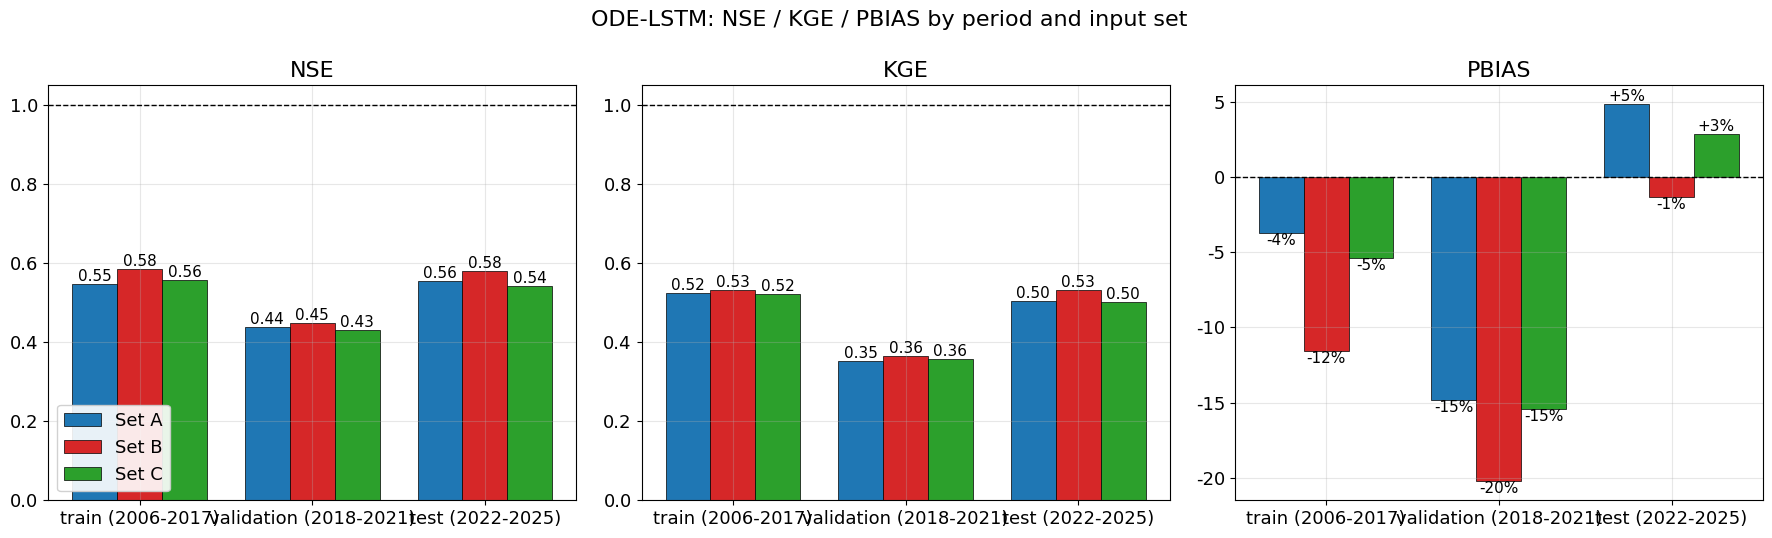

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, metric in zip(axes, ["NSE", "KGE", "PBIAS"]):
    x = np.arange(len(PERIODS))
    w = 0.26
    for i, s in enumerate(SETS):
        vals = [summaries[s]["metrics"][p][metric] for p in PERIODS]
        bars = ax.bar(x + (i - 1) * w, vals, w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}" if metric != "PBIAS" else f"{v:+.0f}%",
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([PERIOD_LABEL[p] for p in PERIODS])
    ax.set_title(metric)
    ax.axhline(common.METRIC_IDEAL[metric], color="black", ls="--", lw=1)
    if metric in ("NSE", "KGE"):
        ax.set_ylim(max(-0.5, min(0, ax.get_ylim()[0])), 1.05)
axes[0].legend(loc="lower left")
fig.suptitle(f"{NAME}: NSE / KGE / PBIAS by period and input set", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_metrics_by_period")
plt.show()

### 4.2 관측 vs 예측 산점도 (로그축)

행 = 기간, 열 = 입력세트. 로그축이므로 저유량(수 m³/s)과 홍수(수천 m³/s)의 거동을 한 그림에서 볼 수 있습니다.
1:1 선 아래로 휘면 고유량 과소, 왼쪽 위로 퍼지면 저유량 과대입니다. 관측값 0 (전체의 약 16%) 은 0.1 로 잘라 표시합니다.

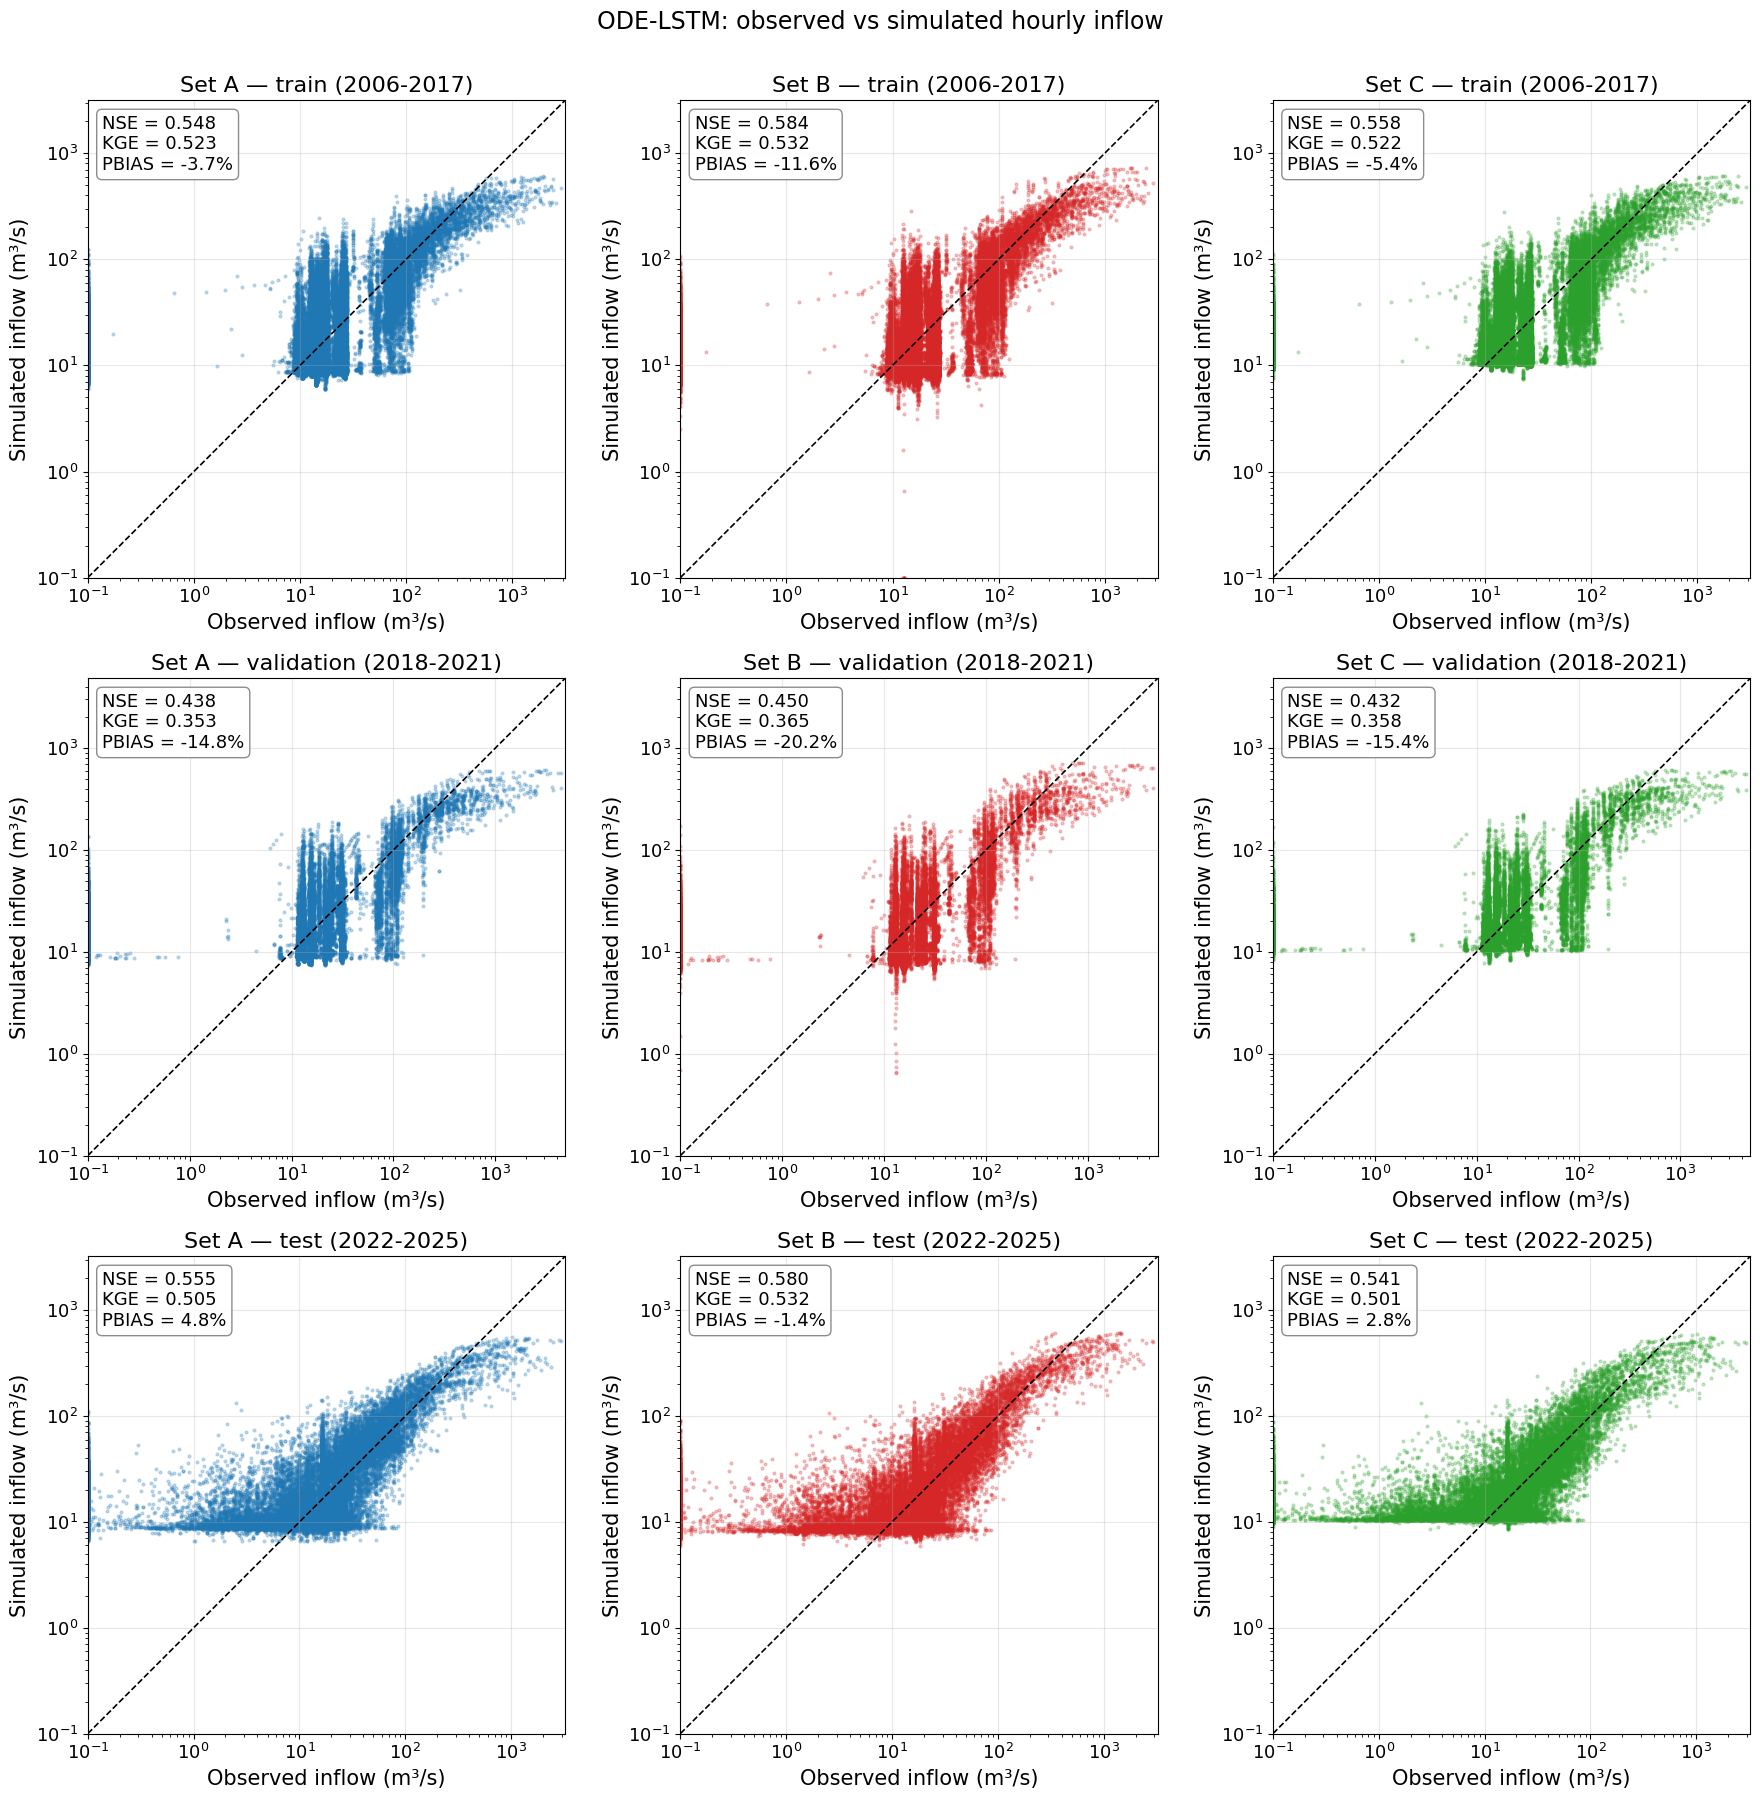

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for i, p in enumerate(PERIODS):
    for j, s in enumerate(SETS):
        df = preds[s][preds[s]["period"] == p]
        common.plot_scatter(df["obs"], df["sim"], title=f"Set {s} — {PERIOD_LABEL[p]}", ax=axes[i, j], color=SET_COLOR[s])
fig.suptitle(f"{NAME}: observed vs simulated hourly inflow", fontsize=17, y=1.0)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_scatter")
plt.show()

## 5. 수문곡선 · 유량지속곡선

### 5.1 테스트 기간(2022–2025) 연도별 수문곡선

각 패널은 한 해의 시간 유입량입니다. 검은 선 = 관측, 색 선 = 입력세트별 예측, 위쪽 막대 = 유역평균 강우(역축).
홍수기(6–9월)의 첨두 크기와 상승·하강 시점, 건기의 저유량 수준을 봅니다.

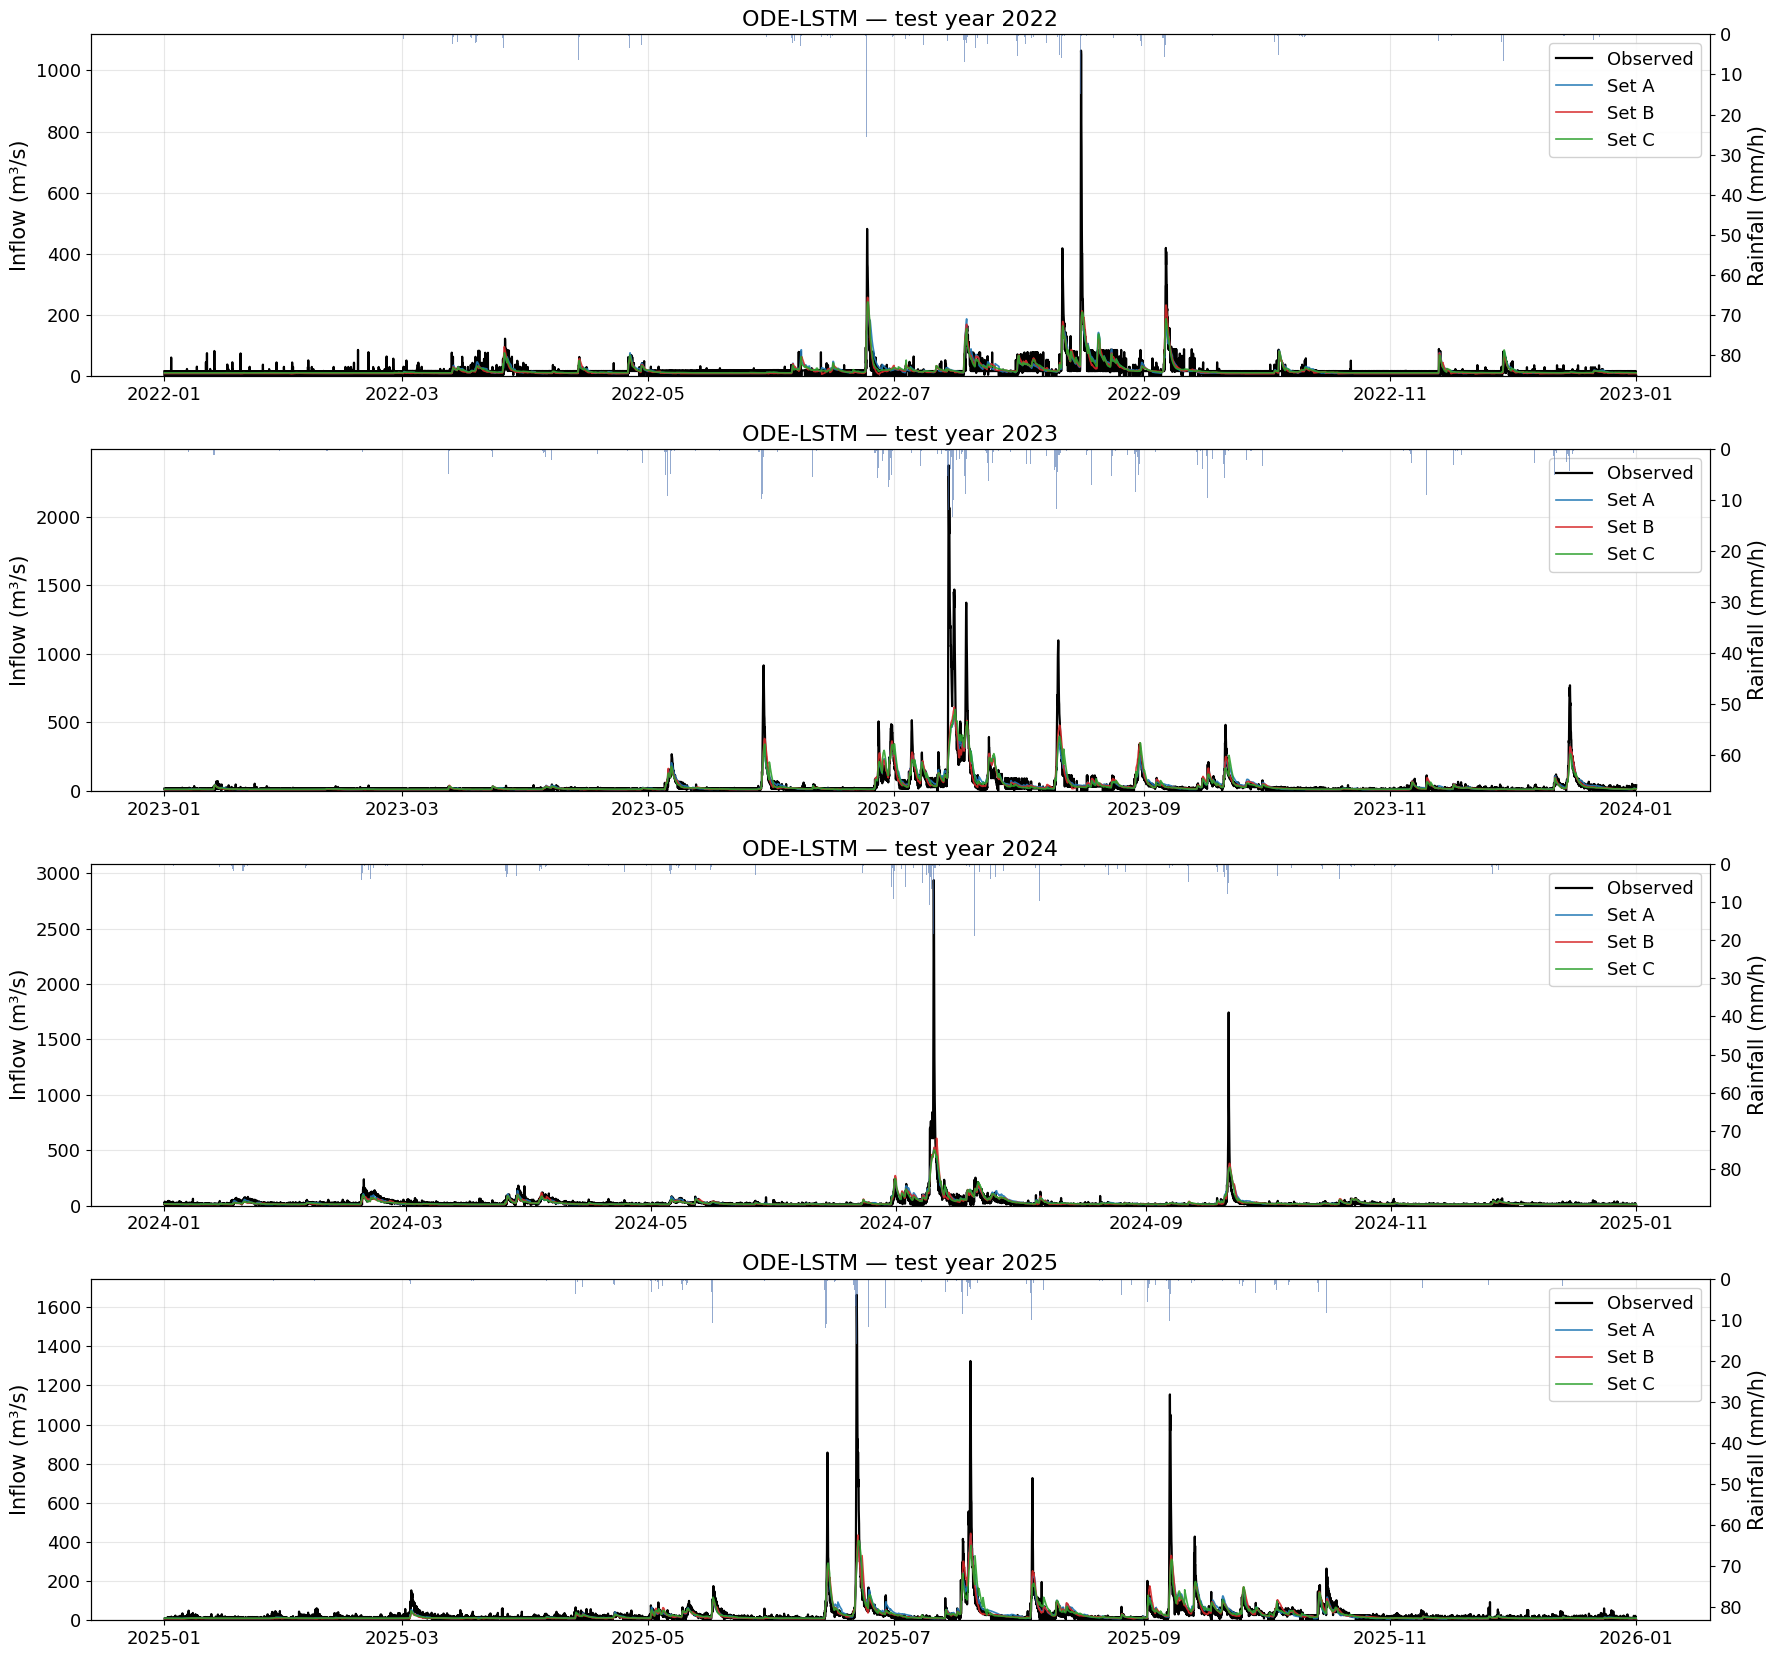

In [9]:
test_years = range(2022, 2026)
fig, axes = plt.subplots(len(test_years), 1, figsize=(18, 4.2 * len(test_years)))
for ax, year in zip(axes, test_years):
    start, end = f"{year}-01-01", f"{year}-12-31 23:00"
    obs = preds["A"].loc[start:end, "obs"]
    common.plot_hydrograph(obs, {f"Set {s}": preds[s].loc[start:end, "sim"] for s in SETS}, rain=rain.loc[start:end],
                           title=f"{NAME} — test year {year}", ax=ax, colors={f"Set {s}": SET_COLOR[s] for s in SETS},
                           styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.2, obs_lw=1.6)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_hydrograph_test")
plt.show()

### 5.2 테스트 기간 최대 홍수사건 3개 확대

관측 첨두가 가장 큰 세 사건을 전후 5일 범위로 확대합니다. 시간 해상도이므로 첨두 **시각**까지 비교할 수 있습니다.

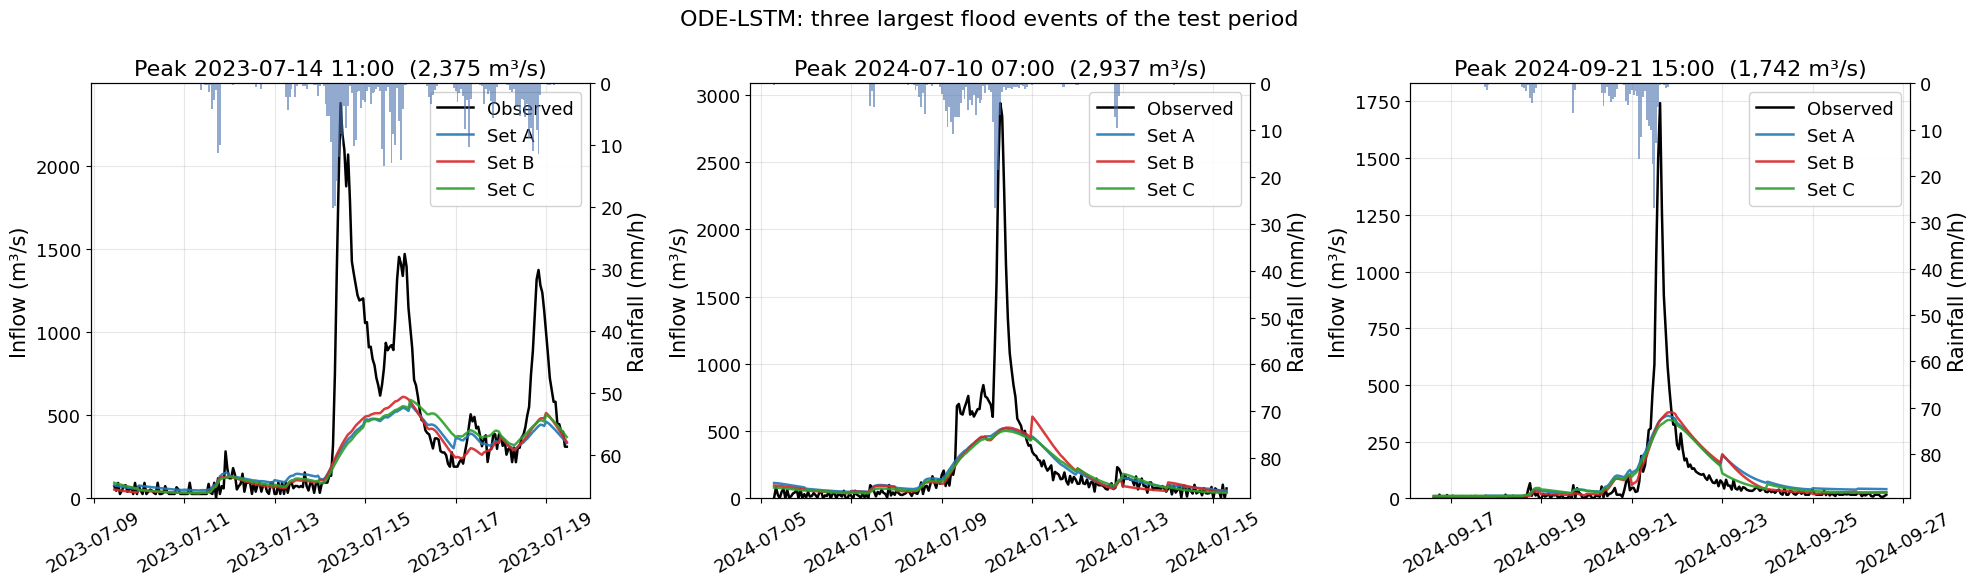

In [10]:
test_obs = preds["A"].loc[preds["A"]["period"] == "test", "obs"]
events = common.detect_events(test_obs, n_events=15)
top3 = sorted(events, key=lambda t: test_obs[t], reverse=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, peak in zip(axes, sorted(top3)):
    start, end = peak - pd.Timedelta(days=5), peak + pd.Timedelta(days=5)
    common.plot_hydrograph(preds["A"]["obs"], {f"Set {s}": preds[s]["sim"] for s in SETS}, rain=rain, start=start, end=end,
                           title=f"Peak {peak:%Y-%m-%d %H:00}  ({test_obs[peak]:,.0f} m³/s)", ax=ax,
                           colors={f"Set {s}": SET_COLOR[s] for s in SETS}, styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.8)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"{NAME}: three largest flood events of the test period", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_events_top3")
plt.show()

### 5.3 유량지속곡선 (테스트 기간)

고유량(FHV, 왼쪽 음영)과 저유량(FLV, 오른쪽 음영) 구간에서 관측 곡선과의 간격이 각각 FHV, FLV 지표에 해당합니다.

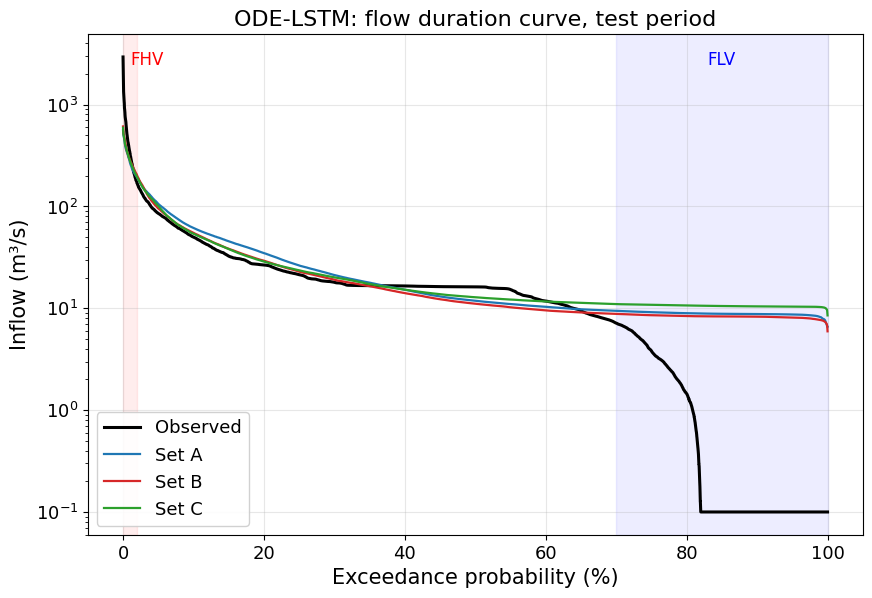

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.5))
common.plot_fdc(test_obs, {f"Set {s}": preds[s].loc[preds[s]["period"] == "test", "sim"] for s in SETS},
                title=f"{NAME}: flow duration curve, test period", colors={f"Set {s}": SET_COLOR[s] for s in SETS}, ax=ax)
common.save_fig(fig, f"{MODEL}_fdc_test")
plt.show()

### 5.4 연도별 NSE

20년 전체를 연도별로 나눠 본 NSE 입니다. 배경 음영은 학습/검증/테스트 기간. 특정 해의 성능 급락은 보통 그 해의 큰 홍수를 놓쳤음을 뜻합니다.

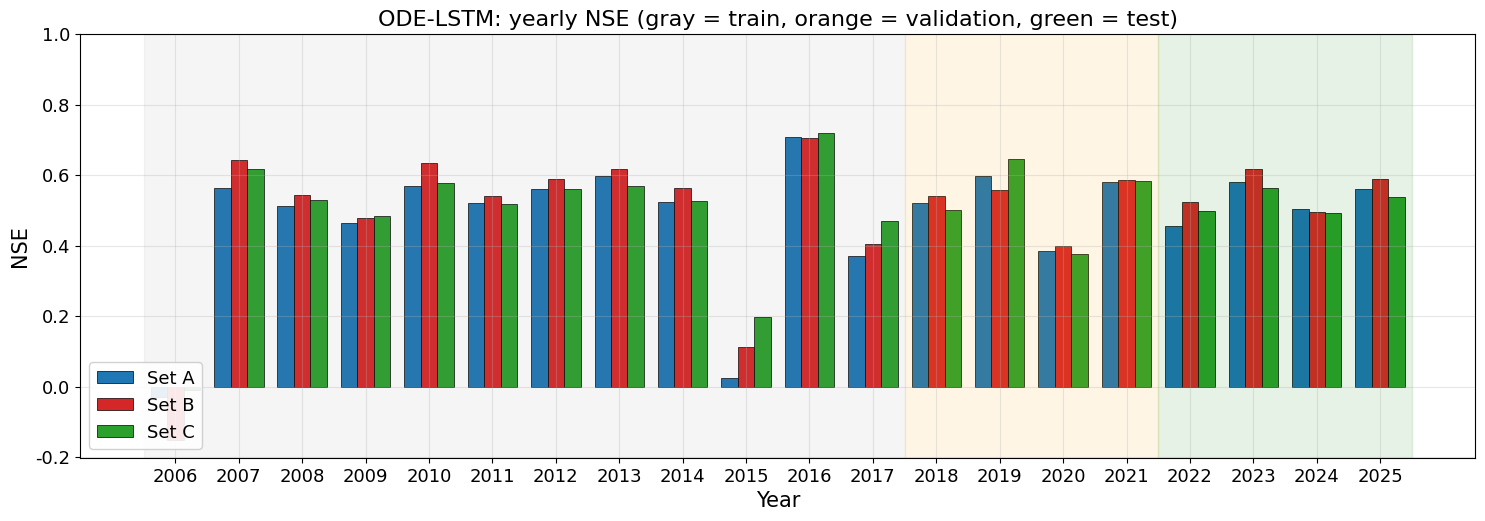

A             B             C       
        NSE    KGE    NSE    KGE    NSE    KGE
year                                          
2006 -0.029 -0.427 -0.152 -0.348 -0.010 -0.365
2007  0.564  0.595  0.642  0.593  0.618  0.582
2008  0.514  0.671  0.544  0.681  0.530  0.599
2009  0.465  0.425  0.478  0.431  0.483  0.449
2010  0.568  0.475  0.634  0.560  0.578  0.490
2011  0.522  0.418  0.540  0.400  0.519  0.423
2012  0.561  0.535  0.590  0.509  0.560  0.533
2013  0.598  0.580  0.617  0.538  0.570  0.541
2014  0.522  0.527  0.562  0.557  0.527  0.527
2015  0.024  0.523  0.111  0.504  0.198  0.530
2016  0.708  0.785  0.705  0.766  0.721  0.737
2017  0.372  0.629  0.404  0.692  0.470  0.671
2018  0.522  0.468  0.541  0.493  0.500  0.471
2019  0.596  0.588  0.558  0.569  0.646  0.598
2020  0.384  0.241  0.398  0.253  0.377  0.246
2021  0.581  0.559  0.586  0.572  0.584  0.565
2022  0.455  0.509  0.524  0.569  0.499  0.510
2023  0.580  0.515  0.619  0.548  0.563  0.525
2024  0.504  0.452  0.495  0.466  0.494  0.437
2025  0.562  0.512  0.588  0.534  0.538  0.492

In [12]:
yearly = {s: common.yearly_metrics(preds[s]) for s in SETS}
fig, ax = plt.subplots(figsize=(18, 5.5))
years = yearly["A"].index
w = 0.26
for i, s in enumerate(SETS):
    ax.bar(years + (i - 1) * w, yearly[s]["NSE"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
ax.set_ylim(max(-1, min(0, np.nanmin([yearly[s]["NSE"].min() for s in SETS]) - 0.05)), 1.0)
ax.set_xticks(years)
ax.set_ylabel("NSE")
ax.set_xlabel("Year")
ax.set_title(f"{NAME}: yearly NSE (gray = train, orange = validation, green = test)")
ax.legend(loc="lower left")
common.save_fig(fig, f"{MODEL}_yearly_nse")
plt.show()
display(pd.concat({s: yearly[s][["NSE", "KGE"]] for s in SETS}, axis=1).round(3))

## 6. 홍수 첨두 재현 (테스트 기간 상위 15개 사건)

관측 첨두를 서로 72시간 이상 떨어지도록 골라 독립 사건 15개를 정의하고, 사건마다

- **첨두 크기 오차** = (예측 첨두 − 관측 첨두) / 관측 첨두 × 100 (%) — 예측 첨두는 관측 첨두 ±24 h 안의 최대값
- **첨두 시각 오차** = 예측 첨두 시각 − 관측 첨두 시각 (h, + 는 지연)
- **사건 체적 오차** = 첨두 전 48 h ~ 후 96 h 구간 총량의 상대오차 (%)
- **사건 NSE** = 같은 구간의 NSE

를 계산합니다. 댐 운영에서는 평균적 적합도(NSE)보다 이 값들이 직접적인 관심사입니다.

In [13]:
event_tables = {s: common.load_saved_events(MODEL, s) for s in SETS}
best_set = max(SETS, key=lambda s: summaries[s]["metrics"]["test"]["NSE"])
print(f"테스트 NSE 가 가장 높은 입력세트: {best_set}")
t = event_tables[best_set].copy()
t[t.select_dtypes("number").columns] = t.select_dtypes("number").round(1)
display(t)
display(pd.DataFrame({s: summaries[s]["events_test"] for s in SETS}).round(2))

테스트 NSE 가 가장 높은 입력세트: B


,obs_peak,sim_peak,sim_peak_time,peak_error_pct,timing_error_h,volume_error_pct,event_NSE
obs_peak_time,,,,,,,
2022-08-16 07:00:00,1064.7,213.3,2022-08-16 13:00:00,-80.0,6.0,-25.8,0.3
2023-05-29 14:00:00,915.1,381.8,2023-05-29 20:00:00,-58.3,6.0,-22.6,0.6
2023-06-27 02:00:00,506.0,275.8,2023-06-27 07:00:00,-45.5,5.0,14.9,0.7
2023-07-05 08:00:00,515.2,281.3,2023-07-05 09:00:00,-45.4,1.0,4.5,0.7
2023-07-14 11:00:00,2375.1,541.5,2023-07-15 11:00:00,-77.2,24.0,-41.1,0.2
2023-07-18 20:00:00,1372.7,513.6,2023-07-19 00:00:00,-62.6,4.0,-21.4,0.6
2023-08-10 16:00:00,1097.7,478.4,2023-08-11 00:00:00,-56.4,8.0,-14.8,0.6
2023-12-15 13:00:00,769.9,322.3,2023-12-15 15:00:00,-58.1,2.0,-20.5,0.6
2024-07-10 07:00:00,2936.9,607.8,2024-07-11 00:00:00,-79.3,17.0,-29.6,0.3


,A,B,C
n_events,15.00,15.00,15.00
peak_error_mean_pct,-69.22,-65.66,-69.76
peak_error_median_pct,-67.95,-66.47,-71.13
peak_abs_error_mean_pct,69.22,65.66,69.76
timing_error_mean_h,5.87,6.47,9.07
timing_abs_error_mean_h,5.87,6.47,9.07
timing_within_3h_frac,0.33,0.33,0.27
peak_within_20pct_frac,0.00,0.00,0.00
volume_error_mean_pct,-12.56,-14.91,-13.48
event_NSE_median,0.52,0.58,0.41


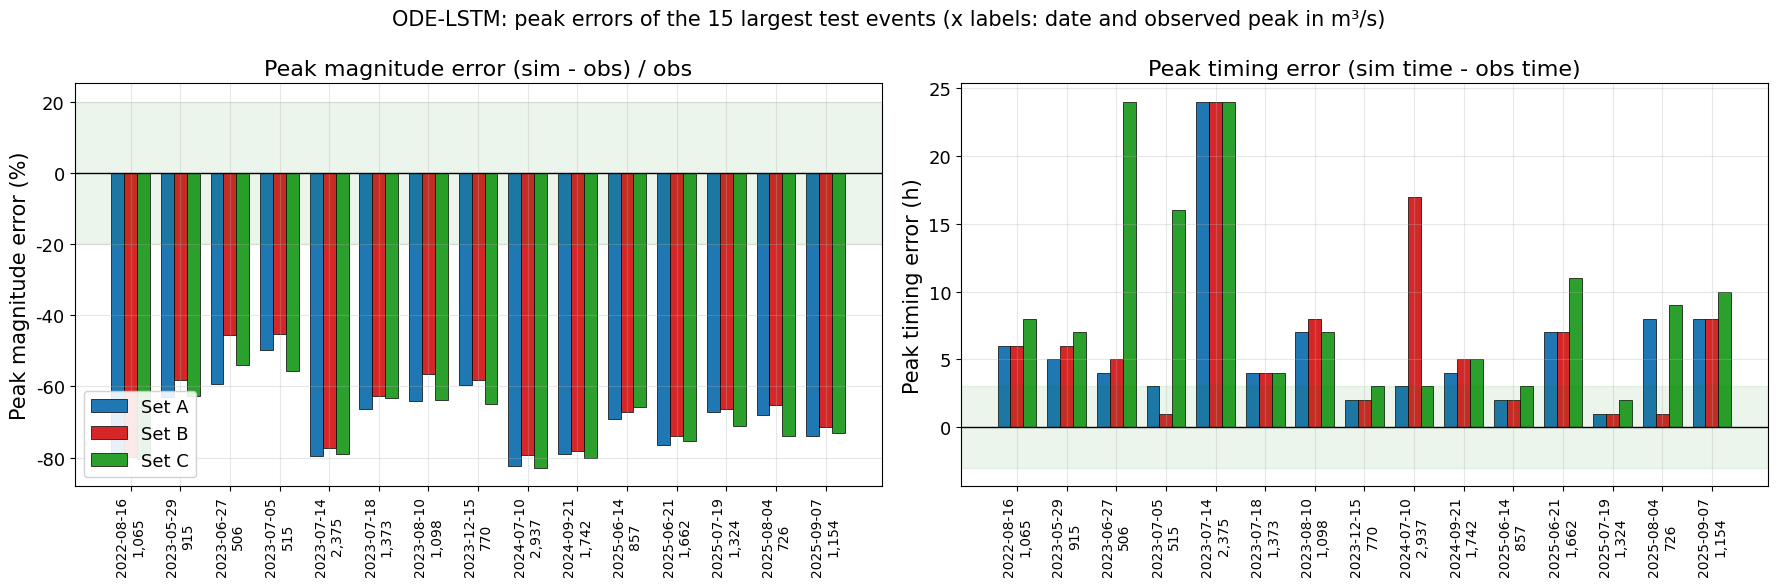

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
table = event_tables["A"]
x = np.arange(len(table))
w = 0.26
for i, s in enumerate(SETS):
    t = event_tables[s].reindex(table.index)
    axes[0].bar(x + (i - 1) * w, t["peak_error_pct"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
    axes[1].bar(x + (i - 1) * w, t["timing_error_h"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
labels = [f"{t:%Y-%m-%d}\n{v:,.0f}" for t, v in zip(table.index, table["obs_peak"])]
for ax, ylabel, title in zip(axes, ["Peak magnitude error (%)", "Peak timing error (h)"],
                             ["Peak magnitude error (sim - obs) / obs", "Peak timing error (sim time - obs time)"]):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=10)
    ax.axhline(0, color="black", lw=1)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].axhspan(-20, 20, color="green", alpha=0.08)
axes[1].axhspan(-3, 3, color="green", alpha=0.08)
axes[0].legend(loc="best")
fig.suptitle(f"{NAME}: peak errors of the 15 largest test events (x labels: date and observed peak in m³/s)", fontsize=15)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_peak_errors")
plt.show()

## 7. 결과 해석

### 7.1 자동 요약 (지표 기반)

아래 글은 `common.narrative_for_run()` 이 지표 값으로부터 규칙적으로 생성한 요약입니다. 모든 모델 노트북에 같은 규칙을 적용하므로
모델 간 서술이 일관됩니다.

In [15]:
for s in SETS:
    display(Markdown(common.narrative_for_run(summaries[s])))

**ODE-LSTM / 입력세트 A (basin-average rainfall)**
- 테스트 기간 NSE 0.555, KGE 0.505, RMSE 57.8 m³/s, PBIAS +4.8%.
- 학습(0.548)·검증(0.438)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 고유량 구간(FHV -37.3%)은 과소 재현되고, 저유량 구간(FLV +94.8%)은 크게 과대 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -67.9%, 평균 절대 첨두오차 69.2%, 첨두 시각 오차 평균 +5.9 h (±3 h 이내 33%, 크기 ±20% 이내 0%).
- 학습: 50 epoch (최대 50 epoch 도달), 최적 epoch 49, epoch당 평균 26 s, 총 학습시간 21.7 min, 파라미터 25,537개.

**ODE-LSTM / 입력세트 B (station rainfall (7 gauges))**
- 테스트 기간 NSE 0.580, KGE 0.532, RMSE 56.2 m³/s, PBIAS -1.4%.
- 학습(0.584)·검증(0.450)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 고유량 구간(FHV -33.2%)은 과소 재현되고, 저유량 구간(FLV +94.2%)은 크게 과대 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -66.5%, 평균 절대 첨두오차 65.7%, 첨두 시각 오차 평균 +6.5 h (±3 h 이내 33%, 크기 ±20% 이내 0%).
- 학습: 50 epoch (최대 50 epoch 도달), 최적 epoch 49, epoch당 평균 27 s, 총 학습시간 22.7 min, 파라미터 27,073개.

**ODE-LSTM / 입력세트 C (basin-average + station rainfall)**
- 테스트 기간 NSE 0.541, KGE 0.501, RMSE 58.7 m³/s, PBIAS +2.8%.
- 학습(0.558)·검증(0.432)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 고유량 구간(FHV -35.3%)은 과소 재현되고, 저유량 구간(FLV +96.2%)은 크게 과대 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -71.1%, 평균 절대 첨두오차 69.8%, 첨두 시각 오차 평균 +9.1 h (±3 h 이내 27%, 크기 ±20% 이내 0%).
- 학습: 45 epoch (early stopping), 최적 epoch 40, epoch당 평균 32 s, 총 학습시간 23.9 min, 파라미터 27,329개.

### 7.2 ODE-LSTM 의 결과 해석

**요약**: 테스트 NSE 0.54–0.58, KGE 0.50–0.53 으로 순환 모델 중 가장 낮고, 특히 **홍수 첨두를 크게 놓친다**(FHV −33 ~ −37%, 첨두 크기
오차 −66 ~ −71%, 첨두 시각 오차 6–9 h).

- **원인 해석**: (1) MTS-LSTM 과 같이 하루 한 샘플 구조라 갱신 횟수가 적고(최적 epoch 40–49, 미수렴), (2) 학습 중 오래된 구간을 1–5 일의
  무작위 해상도로 재집계하므로 **시간 강우의 첨두 강도가 평균화**되어 모델이 급격한 반응을 배우기 어렵다. 시간 단위 자료가 규칙적인 본 자료에서는
  ODE-LSTM 의 "불규칙 샘플링" 장점이 쓸모가 없고 비용만 남는다.
- **수문곡선 형태**: 상승부가 완만하고 첨두가 낮으며 하강부가 길어, 사건 체적 오차(−13 ~ −15%)보다 첨두 오차가 훨씬 크다. 즉 **물은 대체로
  맞지만 시간적으로 퍼져 있다.**
- **입력세트 효과**: 세 세트 간 차이가 0.04 이내로 작다. 관측소별 강우가 도움이 되지 않았다.
- **비용**: 26–32 s/epoch (LSTM 의 3–4배).


## 8. 요약

아래 표가 이 노트북의 최종 결과이며, `results/odelstm_<set>/summary.json` 으로 저장되어 비교 노트북에서 사용됩니다.

In [16]:
summary_table = pd.DataFrame({
    f"Set {s}": {
        "parameters": summaries[s]["n_parameters"],
        "epochs trained": summaries[s]["epochs_trained"],
        "best epoch": summaries[s]["best_epoch"],
        "early stopped": summaries[s]["early_stopped"],
        "s / epoch": round(summaries[s]["epoch_time_mean_s"], 1),
        "training time (min)": round(summaries[s]["train_time_total_s"] / 60, 1),
        "test NSE": round(summaries[s]["metrics"]["test"]["NSE"], 3),
        "test KGE": round(summaries[s]["metrics"]["test"]["KGE"], 3),
        "test RMSE (m³/s)": round(summaries[s]["metrics"]["test"]["RMSE"], 1),
        "test PBIAS (%)": round(summaries[s]["metrics"]["test"]["PBIAS"], 1),
        "test FHV (%)": round(summaries[s]["metrics"]["test"]["FHV"], 1),
        "peak |error| mean (%)": round(summaries[s]["events_test"]["peak_abs_error_mean_pct"], 1),
        "peak |timing| mean (h)": round(summaries[s]["events_test"]["timing_abs_error_mean_h"], 1),
    } for s in SETS})
display(summary_table)
summary_table.to_csv(common.RESULTS_DIR / f"{MODEL}_summary_table.csv")

,Set A,Set B,Set C
parameters,25537,27073,27329
epochs trained,50,50,45
best epoch,49,49,40
early stopped,False,False,True
s / epoch,26.0,27.1,32.0
training time (min),21.7,22.7,23.9
test NSE,0.555,0.58,0.541
test KGE,0.505,0.532,0.501
test RMSE (m³/s),57.8,56.2,58.7
test PBIAS (%),4.8,-1.4,2.8
